# Embudo de conversión y A/B test del checkout
**Mateo Taylor** · Proyecto de portfolio · Data Analyst / Marketing Analytics

**Contexto:** una tienda online quiere vender más sin aumentar la inversión en pauta. Antes de pedir más
tráfico, quiero saber **dónde se pierde la gente en el embudo** y si el nuevo **checkout de una sola página**
realmente mejora la conversión o es ruido.

**Datos:** 8 semanas de sesiones web (1/9 – 26/10/2025) con UTM, dispositivo y etapas del embudo. Desde el
15/9, las sesiones que inician el checkout se asignan al azar a la versión **A (3 pasos, control)** o
**B (una página + pago express)**.
> ⚠️ **Datos simulados** con `generar_datos.py`: no corresponden a ninguna empresa real. El análisis
> funciona igual con un export real de GA4 o de la base de pedidos que respete el esquema.

**Contenido**
1. Calidad de datos: tráfico de bots
2. El embudo completo
3. Canales y dispositivos
4. A/B test del checkout
5. Impacto estimado
6. Conclusiones

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats

VERDE, LIMA, GRIS, TINTA, ROJO, AZUL = "#4f6b00", "#a6cf1f", "#9aa196", "#1d2219", "#c75b46", "#3f9c8f"
plt.rcParams.update({
    "figure.figsize": (10, 4.2), "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9cec4",
    "xtick.color": "#5a6253", "ytick.color": "#5a6253", "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.titlelocation": "left", "axes.titlepad": 12, "axes.grid": True, "grid.color": "#e6e9e1",
    "axes.axisbelow": True, "font.size": 10.5, "legend.frameon": False,
    "axes.prop_cycle": plt.cycler(color=[VERDE, LIMA, AZUL, "#d9a521", ROJO, "#7b6fd1"]),
})
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
ses = pd.read_csv("data/sesiones.csv.gz", parse_dates=["fecha"])
print(f"{len(ses):,} sesiones · {ses['fecha'].min():%d/%m} – {ses['fecha'].max():%d/%m/%Y}")
ses.head()

137,833 sesiones · 01/09 – 26/10/2025


,sesion_id,fecha,utm_source,utm_medium,dispositivo,usuario_nuevo,duracion_seg,paginas_vistas,vio_producto,agrego_carrito,inicio_checkout,compro,ingreso_usd,grupo_test
0,S0002052,2025-09-01,google,cpc,desktop,False,282,4,True,True,True,True,174.490,NaN
1,S0000679,2025-09-01,google,cpc,tablet,True,155,2,True,True,False,False,0.000,NaN
2,S0000925,2025-09-01,google,organic,desktop,True,39,3,False,False,False,False,0.000,NaN
3,S0000802,2025-09-01,instagram,paid_social,mobile,True,24,1,False,False,False,False,0.000,NaN
4,B0000234,2025-09-01,price-crawler.net,referral,desktop,True,0,60,True,False,False,False,0.000,NaN


## 1. Calidad de datos: tráfico de bots
Una señal típica de bot es una sesión de **0 segundos con decenas de páginas vistas**: nadie navega así.
Si no lo limpio, ese tráfico infla las visitas y baja artificialmente la tasa de conversión.

In [2]:
sospechosas = ses[(ses["duracion_seg"] == 0) & (ses["paginas_vistas"] >= 20)]
print(f"Sesiones sospechosas: {len(sospechosas):,} ({len(sospechosas)/len(ses):.1%} del total)")
sospechosas.groupby(["utm_source", "utm_medium"]).size().rename("sesiones").to_frame()

Sesiones sospechosas: 3,361 (2.4% del total)


,,sesiones
utm_source,utm_medium,
price-crawler.net,referral,3361


In [3]:
cr_sucia = ses["compro"].mean()
ses = ses.drop(sospechosas.index)
print(f"Todas vienen de una sola fuente (price-crawler.net), un scraper de precios. Las excluyo.")
print(f"Conversión con bots: {cr_sucia:.2%} → sin bots: {ses['compro'].mean():.2%}")
# chequeo de integridad del experimento: nadie asignado antes del inicio, solo sesiones con checkout
assert ses.loc[ses["fecha"] < "2025-09-15", "grupo_test"].isna().all()
assert ses.loc[ses["grupo_test"].notna(), "inicio_checkout"].all()
print("Integridad del test: OK (sin asignaciones antes del 15/9 ni fuera del checkout)")

Todas vienen de una sola fuente (price-crawler.net), un scraper de precios. Las excluyo.
Conversión con bots: 3.13% → sin bots: 3.21%
Integridad del test: OK (sin asignaciones antes del 15/9 ni fuera del checkout)


## 2. El embudo completo

In [4]:
etapas = ["sesion", "vio_producto", "agrego_carrito", "inicio_checkout", "compro"]
nombres = ["Sesiones", "Vio un producto", "Agregó al carrito", "Inició checkout", "Compró"]
ses["sesion"] = True
emb = pd.DataFrame({"etapa": nombres, "sesiones": [int(ses[e].sum()) for e in etapas]})
emb["% del total"] = emb["sesiones"] / emb["sesiones"].iloc[0]
emb["% de la etapa anterior"] = emb["sesiones"] / emb["sesiones"].shift(1)
emb

,etapa,sesiones,% del total,% de la etapa anterior
0,Sesiones,134472,1.000,NaN
1,Vio un producto,76540,0.569,0.569
2,Agregó al carrito,14281,0.106,0.187
3,Inició checkout,7868,0.059,0.551
4,Compró,4318,0.032,0.549


El 81% de quienes ven un producto no lo agrega al carrito; del checkout, abandona el 45%.


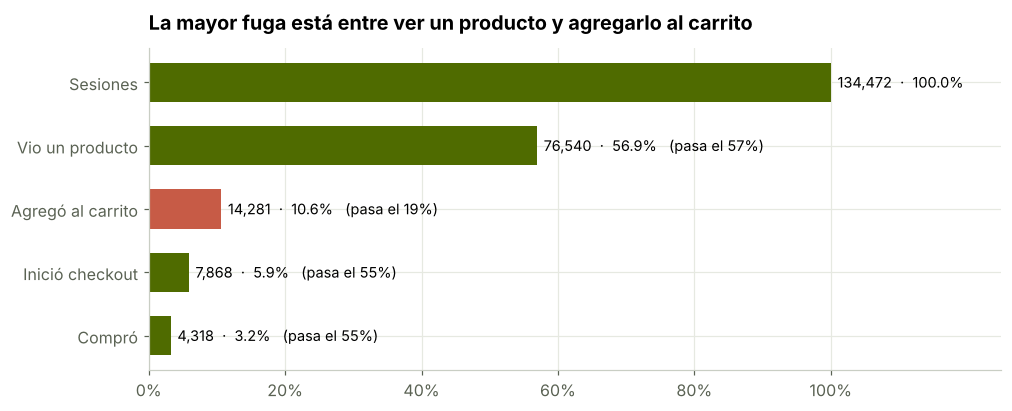

In [5]:
fig, ax = plt.subplots(figsize=(10, 3.8))
y = np.arange(len(emb))[::-1]
ax.barh(y, emb["% del total"], color=[VERDE, VERDE, ROJO, VERDE, VERDE], height=.62)
for yi, (_, r) in zip(y, emb.iterrows()):
    txt = f"{r['sesiones']:,}  ·  {r['% del total']:.1%}"
    if not np.isnan(r["% de la etapa anterior"]):
        txt += f"   (pasa el {r['% de la etapa anterior']:.0%})"
    ax.text(r["% del total"] + .01, yi, txt, va="center", fontsize=9.5)
ax.set_yticks(y, emb["etapa"]); ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_xlim(0, 1.25); ax.set_xticks(np.arange(0, 1.01, .2))
ax.set_title("La mayor fuga está entre ver un producto y agregarlo al carrito")
plt.show()
fuga = 1 - emb.loc[2, "% de la etapa anterior"]
print(f"El {fuga:.0%} de quienes ven un producto no lo agrega al carrito; "
      f"del checkout, abandona el {1 - emb.loc[4, '% de la etapa anterior']:.0%}.")

## 3. Canales y dispositivos
Comparo canales por **tasa de conversión** y **ingreso por sesión** (RPS), que combina conversión y ticket.

In [6]:
ses["canal"] = ses["utm_source"] + " / " + ses["utm_medium"]
canal = ses.groupby("canal").agg(sesiones=("sesion_id", "count"), compras=("compro", "sum"), ingresos=("ingreso_usd", "sum"))
canal["conversion"] = canal["compras"] / canal["sesiones"]
canal["ingreso_por_sesion"] = canal["ingresos"] / canal["sesiones"]
canal["% sesiones"] = canal["sesiones"] / canal["sesiones"].sum()
canal["% ingresos"] = canal["ingresos"] / canal["ingresos"].sum()
canal = canal.sort_values("ingreso_por_sesion", ascending=False)
canal

,sesiones,compras,ingresos,conversion,ingreso_por_sesion,% sesiones,% ingresos
canal,,,,,,,
newsletter / email,11022,835,"71,757.010",0.076,6.510,0.082,0.192
(direct) / (none),18657,847,"73,576.400",0.045,3.944,0.139,0.196
google / organic,24119,898,"78,915.630",0.037,3.272,0.179,0.211
google / cpc,29674,1055,"91,130.350",0.036,3.071,0.221,0.243
blog / referral,6432,157,"13,430.220",0.024,2.088,0.048,0.036
instagram / paid_social,32354,426,"36,727.140",0.013,1.135,0.241,0.098
tiktok / paid_social,12214,100,"9,072.610",0.008,0.743,0.091,0.024


Paid social: 33% de las sesiones y 12% de los ingresos.


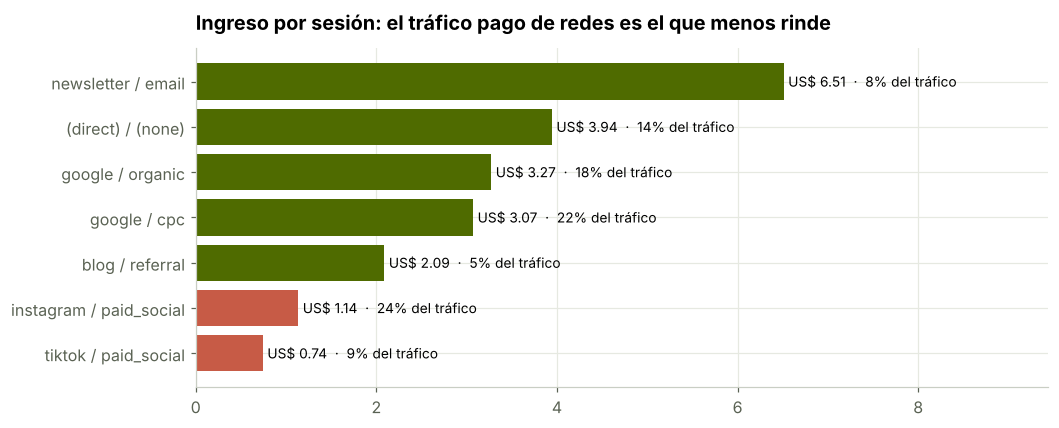

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
c = canal.sort_values("ingreso_por_sesion")
ax.barh(c.index, c["ingreso_por_sesion"], color=[ROJO if v < 2 else VERDE for v in c["ingreso_por_sesion"]])
for i, (v, s) in enumerate(zip(c["ingreso_por_sesion"], c["% sesiones"])):
    ax.text(v + .05, i, f"US$ {v:.2f}  ·  {s:.0%} del tráfico", va="center", fontsize=9)
ax.set_xlim(0, c["ingreso_por_sesion"].max() * 1.45)
ax.set_title("Ingreso por sesión: el tráfico pago de redes es el que menos rinde")
plt.show()

paid = canal.loc[canal.index.str.contains("paid_social")]
print(f"Paid social: {paid['% sesiones'].sum():.0%} de las sesiones y {paid['% ingresos'].sum():.0%} de los ingresos.")

In [8]:
disp = ses.groupby("dispositivo")[["vio_producto", "agrego_carrito", "inicio_checkout", "compro"]].mean()
disp["checkout→compra"] = ses[ses["inicio_checkout"]].groupby("dispositivo")["compro"].mean()
disp["% sesiones"] = ses["dispositivo"].value_counts(normalize=True)
disp.loc[["mobile", "desktop", "tablet"]]

,vio_producto,agrego_carrito,inicio_checkout,compro,checkout→compra,% sesiones
dispositivo,,,,,,
mobile,0.532,0.085,0.044,0.021,0.465,0.679
desktop,0.656,0.158,0.093,0.060,0.645,0.282
tablet,0.586,0.104,0.056,0.031,0.548,0.039


Mobile trae **dos de cada tres sesiones**, pero convierte mucho peor en el último paso: cuando llega al
checkout, completa la compra bastante menos que en desktop. Es exactamente lo que el test intenta resolver.

## 4. A/B test del checkout
**Hipótesis:** un checkout en una sola página con pago express reduce el abandono, sobre todo en mobile.

| | |
|---|---|
| **Unidad** | sesión que inicia el checkout |
| **Métrica principal** | % de checkouts que terminan en compra |
| **Métrica de control** | ticket promedio (que la nueva versión no baje el gasto) |
| **Período** | 15/09 – 26/10/2025 (6 semanas, sin cortar antes de tiempo) |
| **Nivel de significancia** | α = 0,05 (dos colas) · potencia 80 % |

### 4.1 ¿Alcanzaba la muestra? (cálculo previo)
Con la conversión del checkout de las dos semanas previas al test calculo cuántas sesiones por grupo
hacían falta para detectar una mejora de 4 puntos.

In [9]:
pre = ses[(ses["fecha"] < "2025-09-15") & ses["inicio_checkout"]]
p0 = pre["compro"].mean(); mde = .04
z_a, z_b = stats.norm.ppf(1 - .05 / 2), stats.norm.ppf(.80)
p1 = p0 + mde; pbar = (p0 + p1) / 2
n_req = ((z_a * np.sqrt(2 * pbar * (1 - pbar)) + z_b * np.sqrt(p0 * (1 - p0) + p1 * (1 - p1))) ** 2) / mde ** 2
test = ses[ses["grupo_test"].notna()].copy()
print(f"Conversión base del checkout: {p0:.1%}")
print(f"Muestra necesaria: {int(np.ceil(n_req)):,} sesiones por grupo · muestra real: {test['grupo_test'].value_counts().min():,} (mínimo por grupo)")

Conversión base del checkout: 50.8%
Muestra necesaria: 2,444 sesiones por grupo · muestra real: 3,004 (mínimo por grupo)


### 4.2 Control de la asignación (SRM)
Antes de mirar resultados verifico que la división 50/50 haya salido pareja. Un desbalance grande
(*sample ratio mismatch*) indicaría un error de implementación y invalidaría el test.

In [10]:
n = test["grupo_test"].value_counts().sort_index()
chi2, p_srm = stats.chisquare(n.values)
print(f"A: {n['A']:,} · B: {n['B']:,} · p-valor SRM = {p_srm:.3f} → {'asignación OK' if p_srm > .01 else 'REVISAR asignación'}")

A: 3,096 · B: 3,004 · p-valor SRM = 0.239 → asignación OK


### 4.3 Resultado principal

In [11]:
def prop_test(a_conv, a_n, b_conv, b_n):
    pa, pb = a_conv / a_n, b_conv / b_n
    p = (a_conv + b_conv) / (a_n + b_n)
    se0 = np.sqrt(p * (1 - p) * (1 / a_n + 1 / b_n))
    z = (pb - pa) / se0
    se = np.sqrt(pa * (1 - pa) / a_n + pb * (1 - pb) / b_n)
    return {"A": pa, "B": pb, "diferencia": pb - pa, "ic_bajo": pb - pa - 1.96 * se, "ic_alto": pb - pa + 1.96 * se,
            "mejora_relativa": (pb - pa) / pa, "z": z, "p_valor": 2 * (1 - stats.norm.cdf(abs(z)))}

g = test.groupby("grupo_test")["compro"].agg(["sum", "count"])
res = prop_test(g.loc["A", "sum"], g.loc["A", "count"], g.loc["B", "sum"], g.loc["B", "count"])
pd.Series(res).to_frame("resultado")

,resultado
A,0.536
B,0.587
diferencia,0.051
ic_bajo,0.026
ic_alto,0.076
mejora_relativa,0.095
z,4.014
p_valor,0.000


In [12]:
print(f"Conversión del checkout: A {res['A']:.1%} → B {res['B']:.1%}")
print(f"Diferencia: {res['diferencia']*100:+.1f} puntos (IC 95%: {res['ic_bajo']*100:+.1f} a {res['ic_alto']*100:+.1f}) · "
      f"mejora relativa {res['mejora_relativa']:+.1%} · p = {res['p_valor']:.4f}")

Conversión del checkout: A 53.6% → B 58.7%
Diferencia: +5.1 puntos (IC 95%: +2.6 a +7.6) · mejora relativa +9.5% · p = 0.0001


**Ingreso por sesión de checkout (bootstrap).** La métrica que le importa al negocio combina conversión y
ticket. Como su distribución está llena de ceros, uso bootstrap para el intervalo de confianza.

Ingreso por checkout: A US$ 47.27 → B US$ 50.40 · diferencia US$ +3.13 (IC 95%: +0.46 a +5.75)


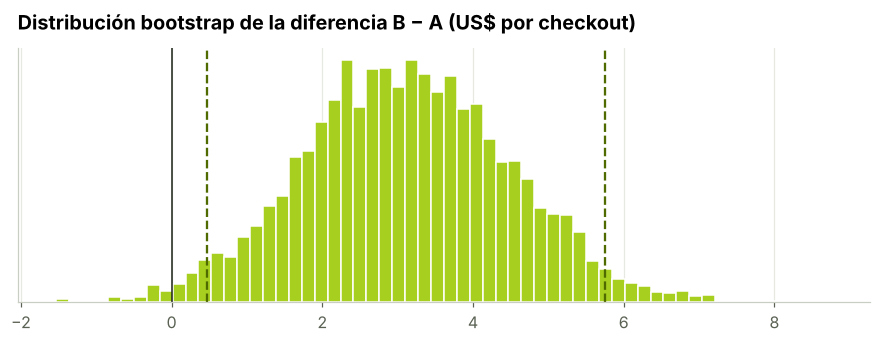

In [13]:
rng = np.random.default_rng(0)
a = test.loc[test["grupo_test"] == "A", "ingreso_usd"].values
b = test.loc[test["grupo_test"] == "B", "ingreso_usd"].values
boot = np.array([rng.choice(b, len(b)).mean() - rng.choice(a, len(a)).mean() for _ in range(5000)])
rps = {"A": a.mean(), "B": b.mean(), "dif": b.mean() - a.mean(), "ic_bajo": np.percentile(boot, 2.5), "ic_alto": np.percentile(boot, 97.5)}
print(f"Ingreso por checkout: A US$ {rps['A']:.2f} → B US$ {rps['B']:.2f} · diferencia US$ {rps['dif']:+.2f} "
      f"(IC 95%: {rps['ic_bajo']:+.2f} a {rps['ic_alto']:+.2f})")

fig, ax = plt.subplots(figsize=(10, 3))
ax.hist(boot, bins=60, color=LIMA, edgecolor="white")
ax.axvline(0, color=TINTA, lw=1); ax.axvline(rps["ic_bajo"], color=VERDE, ls="--"); ax.axvline(rps["ic_alto"], color=VERDE, ls="--")
ax.set_title("Distribución bootstrap de la diferencia B − A (US$ por checkout)"); ax.set_yticks([])
plt.show()

**Métrica de control: ticket promedio.** Verifico que la versión B no haga comprar menos.

In [14]:
ta, tb = test.loc[(test["grupo_test"] == "A") & test["compro"], "ingreso_usd"], test.loc[(test["grupo_test"] == "B") & test["compro"], "ingreso_usd"]
u, p_ticket = stats.mannwhitneyu(ta, tb)
print(f"Ticket A: US$ {ta.mean():.2f} · ticket B: US$ {tb.mean():.2f} · Mann-Whitney p = {p_ticket:.2f} → sin diferencia significativa")

Ticket A: US$ 88.27 · ticket B: US$ 85.93 · Mann-Whitney p = 0.12 → sin diferencia significativa


### 4.4 ¿El efecto es igual en todos los dispositivos?
El análisis por segmento sirve para entender el mecanismo, no para "buscar" un resultado: por eso
aplico la corrección de Bonferroni (3 comparaciones → umbral α = 0,0167).

In [15]:
seg = []
for d in ["mobile", "desktop", "tablet"]:
    t = test[test["dispositivo"] == d].groupby("grupo_test")["compro"].agg(["sum", "count"])
    r = prop_test(t.loc["A", "sum"], t.loc["A", "count"], t.loc["B", "sum"], t.loc["B", "count"])
    seg.append({"dispositivo": d, "n": int(t["count"].sum()), **r, "significativo": r["p_valor"] < .05 / 3})
seg = pd.DataFrame(seg).set_index("dispositivo")
seg[["n", "A", "B", "diferencia", "ic_bajo", "ic_alto", "p_valor", "significativo"]]

,n,A,B,diferencia,ic_bajo,ic_alto,p_valor,significativo
dispositivo,,,,,,,,
mobile,3159,0.440,0.531,0.090,0.056,0.125,0.000,True
desktop,2720,0.645,0.652,0.007,-0.029,0.043,0.706,False
tablet,221,0.560,0.562,0.002,-0.129,0.133,0.981,False


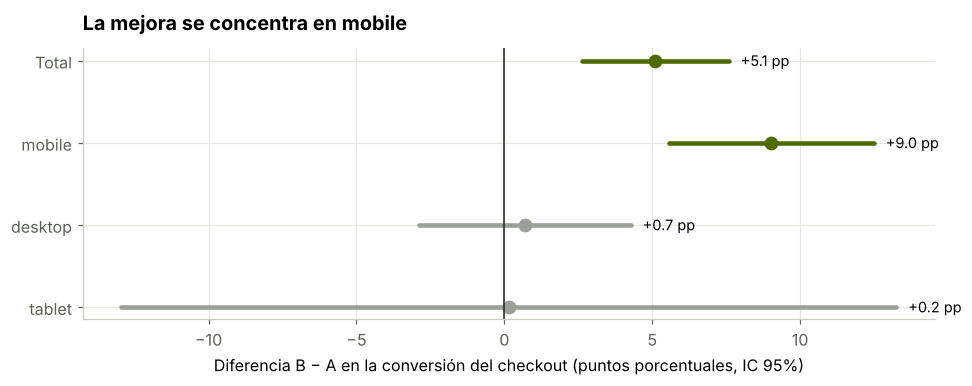

In [16]:
fig, ax = plt.subplots(figsize=(10, 3.2))
filas = [("Total", res)] + [(d, seg.loc[d]) for d in seg.index]
for i, (nom, r) in enumerate(filas[::-1]):
    color = VERDE if r["ic_bajo"] > 0 else GRIS
    ax.plot([r["ic_bajo"] * 100, r["ic_alto"] * 100], [i, i], color=color, lw=3, solid_capstyle="round")
    ax.plot(r["diferencia"] * 100, i, "o", color=color, ms=8)
    ax.text(r["ic_alto"] * 100 + .4, i, f"{r['diferencia']*100:+.1f} pp", va="center", fontsize=9.5)
ax.axvline(0, color=TINTA, lw=1)
ax.set_yticks(range(len(filas)), [f[0] for f in filas[::-1]])
ax.set_xlabel("Diferencia B − A en la conversión del checkout (puntos porcentuales, IC 95%)")
ax.set_title("La mejora se concentra en mobile")
plt.show()

**Estabilidad en el tiempo.** Miro la conversión acumulada día a día para confirmar que la ventaja de B
no es un pico de los primeros días (efecto novedad).

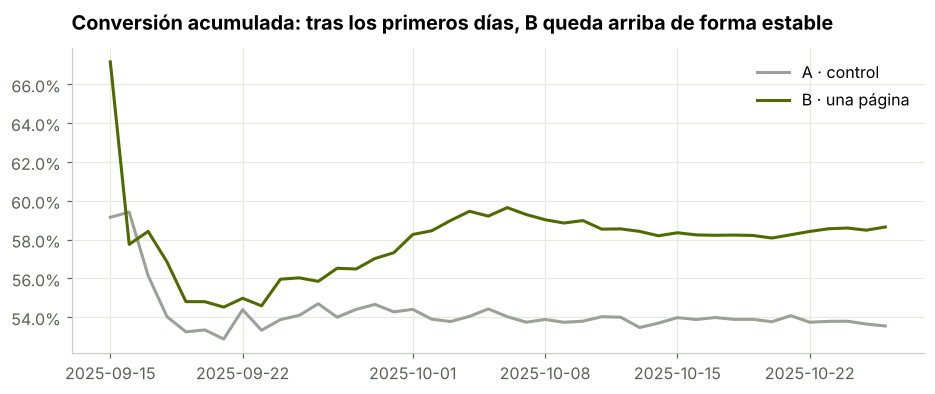

In [17]:
diario = test.groupby(["fecha", "grupo_test"])["compro"].agg(["sum", "count"]).unstack()
acum = diario["sum"].cumsum() / diario["count"].cumsum()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(acum.index, acum["A"], color=GRIS, lw=2, label="A · control")
ax.plot(acum.index, acum["B"], color=VERDE, lw=2, label="B · una página")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.legend()
ax.set_title("Conversión acumulada: tras los primeros días, B queda arriba de forma estable")
plt.show()

## 5. Impacto estimado
Proyecto el efecto a un mes con el volumen de checkouts del período del test. Para los ingresos uso la
diferencia de **ingreso por checkout** del bootstrap (no conversión × ticket), porque ya incorpora que el
ticket de B fue apenas menor.

In [18]:
semanas = test["fecha"].nunique() / 7
checkouts_mes = len(test) / semanas * 4.33
ticket = test.loc[test["compro"], "ingreso_usd"].mean()
imp = {"diferencia": checkouts_mes * rps["dif"], "ic_bajo": checkouts_mes * rps["ic_bajo"], "ic_alto": checkouts_mes * rps["ic_alto"]}
extra = checkouts_mes * res["diferencia"]
print(f"Checkouts por mes: ~{checkouts_mes:,.0f}")
print(f"Compras adicionales por mes: ~{extra:,.0f} (IC 95%: {checkouts_mes*res['ic_bajo']:,.0f} – {checkouts_mes*res['ic_alto']:,.0f})")
print(f"Ingresos adicionales: ~US$ {imp['diferencia']:,.0f} por mes (IC 95%: US$ {imp['ic_bajo']:,.0f} – {imp['ic_alto']:,.0f}) "
      f"· ~US$ {imp['diferencia']*12:,.0f} al año")

Checkouts por mes: ~4,402
Compras adicionales por mes: ~225 (IC 95%: 115 – 334)
Ingresos adicionales: ~US$ 13,797 por mes (IC 95%: US$ 2,046 – 25,316) · ~US$ 165,566 al año


## 6. Conclusiones
**Lo que muestran los datos**
1. **El 2,4 % del tráfico eran bots** de un scraper de precios. Sin limpiarlos, la conversión se subestimaba (3,13 % contra 3,21 % real) y el canal "referral" parecía peor de lo que es.
2. **La mayor fuga del embudo está en la página de producto:** el 81 % de quienes ven un producto no lo agrega al carrito. Después, el checkout pierde al 45 % de quienes lo inician.
3. **Paid social trae el 33 % de las sesiones, pero solo el 12 % de los ingresos.** Instagram rinde US$ 1,14 por sesión y TikTok US$ 0,74, contra US$ 6,51 del newsletter.
4. **Mobile es dos tercios del tráfico y el punto débil del checkout:** completa la compra el 46 % de quienes llegan, contra 65 % en desktop.
5. **El checkout de una página gana.** La conversión del checkout pasa de 53,6 % a 58,7 % (+5,1 puntos, IC 95 % de +2,6 a +7,6; p < 0,001). El ingreso por checkout sube US$ 3,13 (IC de +0,46 a +5,75) y el ticket no cae de forma significativa.
6. **La mejora es casi toda de mobile:** +9,0 puntos en mobile, frente a un efecto no significativo en desktop (+0,7) y tablet. El test tenía muestra suficiente (más de 3.000 por grupo contra 2.444 necesarias) y la asignación salió pareja (SRM p = 0,24).

**Decisión y recomendaciones**
- **Lanzar la versión B para todo el tráfico.** El impacto esperado es de unas 225 compras y unos US$ 14.000 más por mes (rango del IC: US$ 2.000 – 25.000).
- **Siguiente test: la página de producto**, donde está la mayor fuga. Por ejemplo, mostrar envío y cuotas arriba del botón de compra, y fotos con talle real.
- **Revisar la inversión en paid social:** medir su aporte con una ventana de atribución más larga antes de recortar. Si no aparece valor a lo largo de varias visitas, mover presupuesto a captación de suscriptores del newsletter.
- **Dejar un filtro de bots permanente** en la herramienta de analítica (duración 0 y más de 20 páginas) y una alerta si aparece una fuente nueva con ese patrón.

**Limitaciones:** la asignación es por sesión, no por usuario, así que una misma persona pudo ver las dos versiones. En producción conviene asignar por usuario o por cookie. El efecto de largo plazo (recompra) no se mide en este test.

In [19]:
out = {
    "limpieza": {"bots": int(len(sospechosas)), "cr_sucia": float(cr_sucia), "cr_limpia": float(ses["compro"].mean()), "sesiones": int(len(ses))},
    "embudo": emb.replace({np.nan: None}).to_dict("records"),
    "canales": canal.reset_index().to_dict("records"),
    "dispositivos": disp.reset_index().to_dict("records"),
    "test": {"p0": float(p0), "n_req": int(np.ceil(n_req)), "n": {k: int(v) for k, v in n.items()}, "p_srm": float(p_srm),
             "res": {k: float(v) for k, v in res.items()}, "rps": {k: float(v) for k, v in rps.items()},
             "ticket": {"A": float(ta.mean()), "B": float(tb.mean()), "p": float(p_ticket)},
             "seg": seg.reset_index().assign(significativo=lambda d: d["significativo"].astype(bool)).to_dict("records"),
             "acum": {"fechas": [f.strftime("%d/%m") for f in acum.index], "A": acum["A"].round(4).tolist(), "B": acum["B"].round(4).tolist()}},
    "impacto": {"checkouts_mes": float(checkouts_mes), "ticket": float(ticket), "compras_extra": float(extra), **{k: float(v) for k, v in imp.items()}},
}
dest = Path("../../marketing"); dest.mkdir(parents=True, exist_ok=True)
(dest / "data.json").write_text(json.dumps(out, ensure_ascii=False, default=float))
print("Datos del dashboard exportados:", dest / "data.json")

Datos del dashboard exportados: ../../marketing/data.json
